# Analisis Eksperimen Prompting LLM untuk Deteksi Kerentanan Java

Notebook ini menganalisis 16 berkas ringkasan eksperimen: **DeepSeek Coder 6.7B** dan **Gemma4 E4B (thinking aktif)**, masing-masing dengan 8 kombinasi strategi prompting dan input (kode saja vs kode + FindSecBugs).

## Tujuan analisis
1. Memeriksa kelengkapan dan validitas keluaran setiap skenario.
2. Membandingkan proporsi prediksi rentan, jumlah keluaran valid, respons tidak valid, dan waktu inferensi.
3. Menganalisis distribusi CWE yang diprediksi.
4. Memvisualisasikan hasil **secara terpisah untuk tiap model** agar grafik tidak terlalu panjang.
5. Menghitung metrik deteksi dan klasifikasi terhadap ground truth **hanya jika berkas label ground truth tersedia**.

> **Batasan penting:** berkas `.summary.json` yang diberikan berisi prediksi model dan statistik parsing, tetapi tidak memuat label ground truth per sampel. Karena itu, notebook ini tidak menyebut jumlah prediksi rentan sebagai true positive dan tidak menghitung accuracy, precision, recall, F1, atau false-positive rate tanpa ground truth. Prediksi rentan bukan berarti benar-benar rentan.

## 1. Persiapan dan pemuatan data

Notebook membaca berkas `*.summary.json` dari folder `results/llm/raw/normalized`.

In [1]:
from pathlib import Path
import json, re, math
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

# Berkas hasil yang dinormalisasi dibaca secara khusus dari folder normalized.
# Fallback relatif menjaga notebook tetap dapat dijalankan dari root repository atau folder raw.
normalized_candidates = [
    Path.cwd() / "normalized",
    Path.cwd() / "results" / "llm" / "raw" / "normalized",
    Path("results/llm/raw/normalized"),
]
DATA_DIR = next((folder for folder in normalized_candidates if folder.exists() and list(folder.glob("*.summary.json"))), None)
if DATA_DIR is None:
    raise FileNotFoundError("Tidak ditemukan berkas *.summary.json pada results/llm/raw/normalized.")
DATA_DIR = DATA_DIR.resolve()
SUMMARY_FILES = sorted(DATA_DIR.glob("*.summary.json"))

strategy_order = ["zero-shot", "cot", "tot", "baseline-1", "baseline-2"]
strategy_names = {
    "zero-shot-none": "zero-shot", "zero-shot-findsecbugs": "zero-shot",
    "cot-none": "cot", "cot-findsecbugs": "cot",
    "tot-none": "tot", "tot-findsecbugs": "tot",
}

def normalize_strategy(value):
    value = str(value).strip().lower()
    if value in strategy_names:
        return strategy_names[value]
    value = re.sub(r"-(?:none|findsecbugs)$", "", value)
    return value if value in strategy_order else value

records = []
predictions_by_scenario = {}
for path in SUMMARY_FILES:
    with path.open(encoding="utf-8") as f:
        d = json.load(f)

    model_raw = str(d.get("model", path.name.split("__")[0]))
    model = "DeepSeek Coder 6.7B" if "deepseek" in model_raw.lower() else (
        "Gemma4 E4B (thinking aktif)" if "gemma" in model_raw.lower() else model_raw
    )
    scenario = normalize_strategy(d.get("scenario_id", "unknown"))
    sast_raw = d.get("sast", "unknown")
    sast = "Code + FindSecBugs" if sast_raw == "findsecbugs" else (
        "Code only" if sast_raw == "none" else str(sast_raw)
    )
    valid = int(d.get("predictions_valid", 0))
    total = int(d.get("dataset_records", 0))
    invalid = int(d.get("invalid_responses", max(total-valid, 0)))
    elapsed = float(d.get("elapsed_seconds", np.nan))
    preds = d.get("predictions", []) or []
    key = (model, scenario, sast)
    predictions_by_scenario[key] = preds

    vulnerable = int(d.get("vulnerable_detected_by_model", 0))
    records.append({
        "file": path.name, "model": model, "scenario": scenario, "sast": sast,
        "dataset_records": total, "predictions_valid": valid,
        "invalid_responses": invalid, "failed_calls": int(d.get("failed_calls", 0)),
        "missing_predictions": int(d.get("missing_predictions", 0)),
        "predicted_vulnerable": vulnerable,
        "predicted_not_vulnerable": int(d.get("classified_not_vulnerable_by_model", 0)),
        "vulnerable_with_cwe": int(d.get("vulnerable_predictions_with_cwe", 0)),
        "elapsed_seconds": elapsed,
        "elapsed_hours": elapsed/3600 if not np.isnan(elapsed) else np.nan,
        "valid_rate_pct": 100*valid/total if total else np.nan,
        "invalid_rate_pct": 100*invalid/total if total else np.nan,
        "predicted_vulnerable_pct_of_valid": 100*vulnerable/valid if valid else np.nan,
        "generated_at_utc": d.get("generated_at_utc"), "dataset_sha256": d.get("dataset_sha256"),
        "predictions_list_length": len(preds),
    })

summary = pd.DataFrame(records)
summary["scenario"] = pd.Categorical(summary["scenario"].astype("string"), categories=strategy_order, ordered=True)
summary["scenario_label"] = summary["scenario"].astype("string").fillna("unknown")
summary = summary.sort_values(["model", "sast", "scenario"]).reset_index(drop=True)
print(f"Direktori data: {DATA_DIR}")
print(f"Jumlah berkas ringkasan: {len(summary)}")
print(f"Jumlah sampel target: {sorted(summary['dataset_records'].dropna().unique().tolist())}")
display(summary[["model","scenario_label","sast","dataset_records","predictions_valid","invalid_responses",
                 "valid_rate_pct","predicted_vulnerable","predicted_not_vulnerable",
                 "elapsed_hours","failed_calls","dataset_sha256"]].round(2))


Direktori data: /home/nasyikhqusyairy/Projects/repositories/sast-llm-benchmark/results/llm/raw/normalized
Jumlah berkas ringkasan: 16
Jumlah sampel target: [2740]


,model,scenario_label,sast,dataset_records,predictions_valid,invalid_responses,valid_rate_pct,predicted_vulnerable,predicted_not_vulnerable,elapsed_hours,failed_calls,dataset_sha256
0,DeepSeek Coder 6.7B,zero-shot,Code + FindSecBugs,2740,2740,0,100.00,2645,95,3.60,0,dc4dbfe4f54772afe441369580278780f6de1fcd306f18...
1,DeepSeek Coder 6.7B,cot,Code + FindSecBugs,2740,2740,0,100.00,2644,96,4.37,0,dc4dbfe4f54772afe441369580278780f6de1fcd306f18...
2,DeepSeek Coder 6.7B,tot,Code + FindSecBugs,2740,2740,0,100.00,2667,73,3.11,0,dc4dbfe4f54772afe441369580278780f6de1fcd306f18...
3,DeepSeek Coder 6.7B,baseline-2,Code + FindSecBugs,2740,2740,0,100.00,2639,101,2.95,0,dc4dbfe4f54772afe441369580278780f6de1fcd306f18...
4,DeepSeek Coder 6.7B,zero-shot,Code only,2740,2740,0,100.00,1571,1169,3.20,0,dc4dbfe4f54772afe441369580278780f6de1fcd306f18...
5,DeepSeek Coder 6.7B,cot,Code only,2740,2740,0,100.00,863,1877,2.67,0,dc4dbfe4f54772afe441369580278780f6de1fcd306f18...
6,DeepSeek Coder 6.7B,tot,Code only,2740,2737,3,99.89,2232,505,3.40,3,dc4dbfe4f54772afe441369580278780f6de1fcd306f18...
7,DeepSeek Coder 6.7B,baseline-1,Code only,2740,2740,0,100.00,1580,1160,2.74,0,dc4dbfe4f54772afe441369580278780f6de1fcd306f18...
8,Gemma4 E4B (thinking aktif),zero-shot,Code + FindSecBugs,2740,2600,140,94.89,1917,683,5.70,0,dc4dbfe4f54772afe441369580278780f6de1fcd306f18...
9,Gemma4 E4B (thinking aktif),cot,Code + FindSecBugs,2740,2354,386,85.91,1702,652,6.89,0,dc4dbfe4f54772afe441369580278780f6de1fcd306f18...


## 2. Pemeriksaan konsistensi eksperimen

Bagian ini memeriksa apakah semua skenario menggunakan hash dataset yang sama, apakah jumlah sampel konsisten, dan apakah keluaran valid ditambah respons tidak valid sesuai dengan ukuran dataset. Ketidaksesuaian ditampilkan untuk ditinjau, bukan diperbaiki diam-diam.

In [2]:
print("Hash dataset:")
display(summary.groupby("model")["dataset_sha256"].nunique().rename("jumlah_hash_unik").to_frame())

print("Jumlah record dataset per model:")
display(summary.groupby("model")["dataset_records"].agg(["min","max","nunique"]))

summary["valid_plus_invalid"] = summary["predictions_valid"] + summary["invalid_responses"]
summary["count_gap"] = summary["dataset_records"] - summary["valid_plus_invalid"]
summary["prediction_list_gap"] = summary["predictions_valid"] - summary["predictions_list_length"]

display(summary[["model","scenario","sast","dataset_records","predictions_valid",
                 "invalid_responses","valid_plus_invalid","count_gap",
                 "predictions_list_length","prediction_list_gap","missing_predictions",
                 "failed_calls"]])


Hash dataset:


,jumlah_hash_unik
model,
DeepSeek Coder 6.7B,1
Gemma4 E4B (thinking aktif),1


Jumlah record dataset per model:


,min,max,nunique
model,,,
DeepSeek Coder 6.7B,2740,2740,1
Gemma4 E4B (thinking aktif),2740,2740,1


,model,scenario,sast,dataset_records,predictions_valid,invalid_responses,valid_plus_invalid,count_gap,predictions_list_length,prediction_list_gap,missing_predictions,failed_calls
0,DeepSeek Coder 6.7B,zero-shot,Code + FindSecBugs,2740,2740,0,2740,0,2740,0,0,0
1,DeepSeek Coder 6.7B,cot,Code + FindSecBugs,2740,2740,0,2740,0,2740,0,0,0
2,DeepSeek Coder 6.7B,tot,Code + FindSecBugs,2740,2740,0,2740,0,2740,0,0,0
3,DeepSeek Coder 6.7B,baseline-2,Code + FindSecBugs,2740,2740,0,2740,0,2740,0,0,0
4,DeepSeek Coder 6.7B,zero-shot,Code only,2740,2740,0,2740,0,2740,0,0,0
5,DeepSeek Coder 6.7B,cot,Code only,2740,2740,0,2740,0,2740,0,0,0
6,DeepSeek Coder 6.7B,tot,Code only,2740,2737,3,2740,0,2737,0,0,3
7,DeepSeek Coder 6.7B,baseline-1,Code only,2740,2740,0,2740,0,2740,0,0,0
8,Gemma4 E4B (thinking aktif),zero-shot,Code + FindSecBugs,2740,2600,140,2740,0,2600,0,0,0
9,Gemma4 E4B (thinking aktif),cot,Code + FindSecBugs,2740,2354,386,2740,0,2354,0,0,0


## 3. Ringkasan lintas skenario

Tabel ini bersifat deskriptif. Kolom `predicted_vulnerable` menunjukkan berapa banyak keluaran valid yang menyatakan sampel rentan, **bukan** berapa banyak kerentanan yang berhasil dideteksi dengan benar.

In [3]:
overview = summary[[
    "model","scenario","sast","predictions_valid","valid_rate_pct",
    "predicted_vulnerable","predicted_not_vulnerable",
    "predicted_vulnerable_pct_of_valid","invalid_responses",
    "invalid_rate_pct","elapsed_hours"
]].copy()
display(overview.round(2))


,model,scenario,sast,predictions_valid,valid_rate_pct,predicted_vulnerable,predicted_not_vulnerable,predicted_vulnerable_pct_of_valid,invalid_responses,invalid_rate_pct,elapsed_hours
0,DeepSeek Coder 6.7B,zero-shot,Code + FindSecBugs,2740,100.00,2645,95,96.53,0,0.00,3.60
1,DeepSeek Coder 6.7B,cot,Code + FindSecBugs,2740,100.00,2644,96,96.50,0,0.00,4.37
2,DeepSeek Coder 6.7B,tot,Code + FindSecBugs,2740,100.00,2667,73,97.34,0,0.00,3.11
3,DeepSeek Coder 6.7B,baseline-2,Code + FindSecBugs,2740,100.00,2639,101,96.31,0,0.00,2.95
4,DeepSeek Coder 6.7B,zero-shot,Code only,2740,100.00,1571,1169,57.34,0,0.00,3.20
5,DeepSeek Coder 6.7B,cot,Code only,2740,100.00,863,1877,31.50,0,0.00,2.67
6,DeepSeek Coder 6.7B,tot,Code only,2737,99.89,2232,505,81.55,3,0.11,3.40
7,DeepSeek Coder 6.7B,baseline-1,Code only,2740,100.00,1580,1160,57.66,0,0.00,2.74
8,Gemma4 E4B (thinking aktif),zero-shot,Code + FindSecBugs,2600,94.89,1917,683,73.73,140,5.11,5.70
9,Gemma4 E4B (thinking aktif),cot,Code + FindSecBugs,2354,85.91,1702,652,72.30,386,14.09,6.89


# Analisis khusus: DeepSeek Coder 6.7B

Seluruh grafik pada bagian ini hanya menampilkan model ini. Perbandingan DeepSeek dan Gemma tidak digabungkan dalam satu kanvas.

In [4]:
model_name = 'DeepSeek Coder 6.7B'
dfm = summary[summary["model"] == model_name].copy()
dfm["scenario_label"] = dfm["scenario"].astype("string").fillna("unknown")

display(dfm[["scenario_label","sast","predictions_valid","valid_rate_pct",
             "predicted_vulnerable","predicted_not_vulnerable",
             "predicted_vulnerable_pct_of_valid","invalid_responses",
             "elapsed_hours"]].round(2))


,scenario_label,sast,predictions_valid,valid_rate_pct,predicted_vulnerable,predicted_not_vulnerable,predicted_vulnerable_pct_of_valid,invalid_responses,elapsed_hours
0,zero-shot,Code + FindSecBugs,2740,100.00,2645,95,96.53,0,3.60
1,cot,Code + FindSecBugs,2740,100.00,2644,96,96.50,0,4.37
2,tot,Code + FindSecBugs,2740,100.00,2667,73,97.34,0,3.11
3,baseline-2,Code + FindSecBugs,2740,100.00,2639,101,96.31,0,2.95
4,zero-shot,Code only,2740,100.00,1571,1169,57.34,0,3.20
5,cot,Code only,2740,100.00,863,1877,31.50,0,2.67
6,tot,Code only,2737,99.89,2232,505,81.55,3,3.40
7,baseline-1,Code only,2740,100.00,1580,1160,57.66,0,2.74


### DeepSeek Coder 6.7B: Valid output rate per scenario


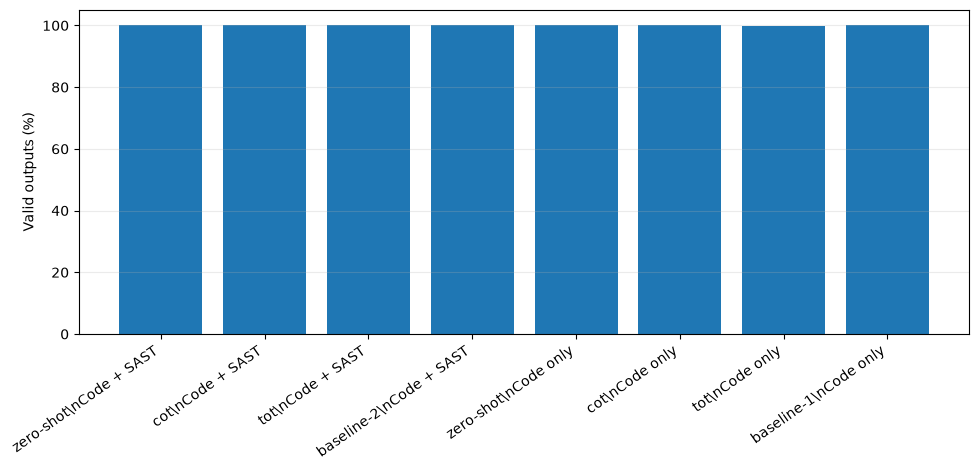

In [5]:
# Grafik deepseek: tingkat keluaran valid
plot_df = dfm.copy()
labels = plot_df["scenario_label"] + "\\n" + plot_df["sast"].replace({"Code only":"Code only","Code + FindSecBugs":"Code + SAST"})
plt.figure(figsize=(10, 4.8))
plt.bar(labels, plot_df["valid_rate_pct"])
plt.ylabel("Valid outputs (%)")
plt.ylim(0, 105)
plt.xticks(rotation=35, ha="right")
plt.grid(axis="y", alpha=.25)
plt.tight_layout()
plt.show()


### DeepSeek Coder 6.7B: Binary decision distribution


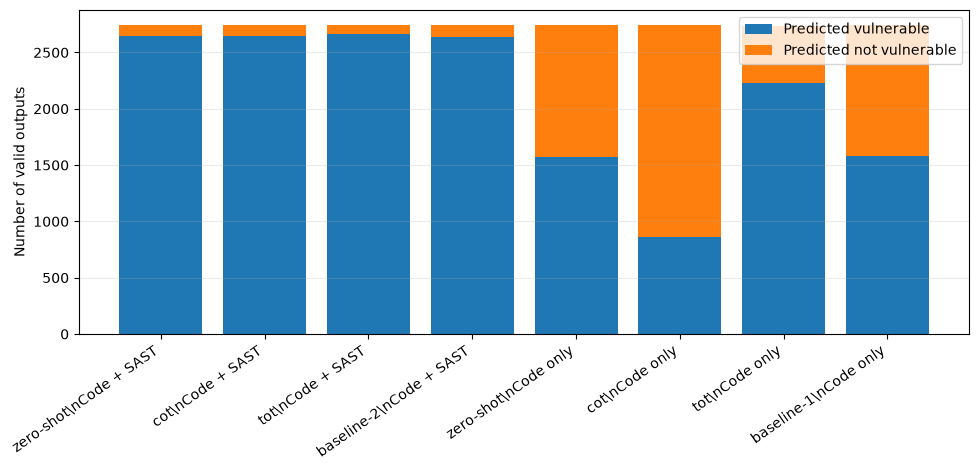

In [6]:
# Grafik deepseek: jumlah label rentan yang dikeluarkan model
plot_df = dfm.copy()
labels = plot_df["scenario_label"] + "\\n" + plot_df["sast"].replace({"Code only":"Code only","Code + FindSecBugs":"Code + SAST"})
plt.figure(figsize=(10, 4.8))
plt.bar(labels, plot_df["predicted_vulnerable"], label="Predicted vulnerable")
plt.bar(labels, plot_df["predicted_not_vulnerable"],
        bottom=plot_df["predicted_vulnerable"], label="Predicted not vulnerable")
plt.ylabel("Number of valid outputs")
plt.xticks(rotation=35, ha="right")
plt.legend()
plt.grid(axis="y", alpha=.25)
plt.tight_layout()
plt.show()


### DeepSeek Coder 6.7B: Share of valid outputs classified as vulnerable


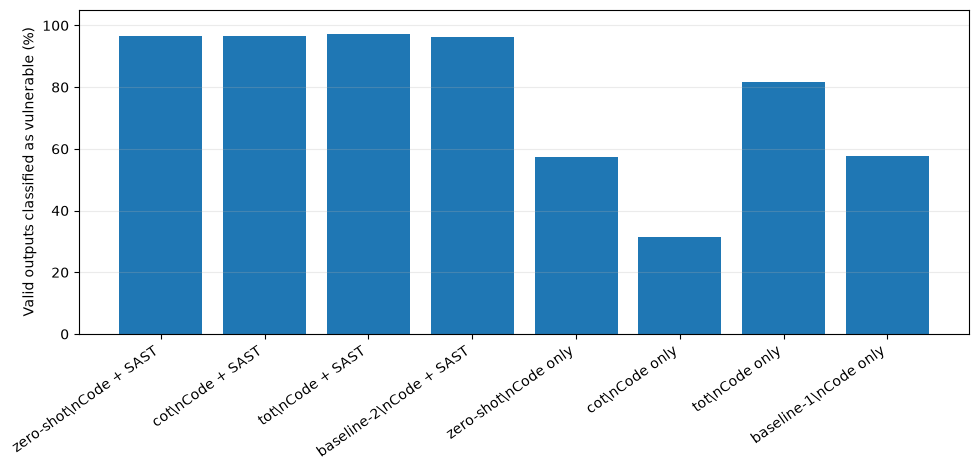

In [7]:
# Grafik deepseek: proporsi prediksi rentan di antara keluaran valid
plot_df = dfm.copy()
labels = plot_df["scenario_label"] + "\\n" + plot_df["sast"].replace({"Code only":"Code only","Code + FindSecBugs":"Code + SAST"})
plt.figure(figsize=(10, 4.8))
plt.bar(labels, plot_df["predicted_vulnerable_pct_of_valid"])
plt.ylabel("Valid outputs classified as vulnerable (%)")
plt.ylim(0, 105)
plt.xticks(rotation=35, ha="right")
plt.grid(axis="y", alpha=.25)
plt.tight_layout()
plt.show()


### DeepSeek Coder 6.7B: Total elapsed time per scenario


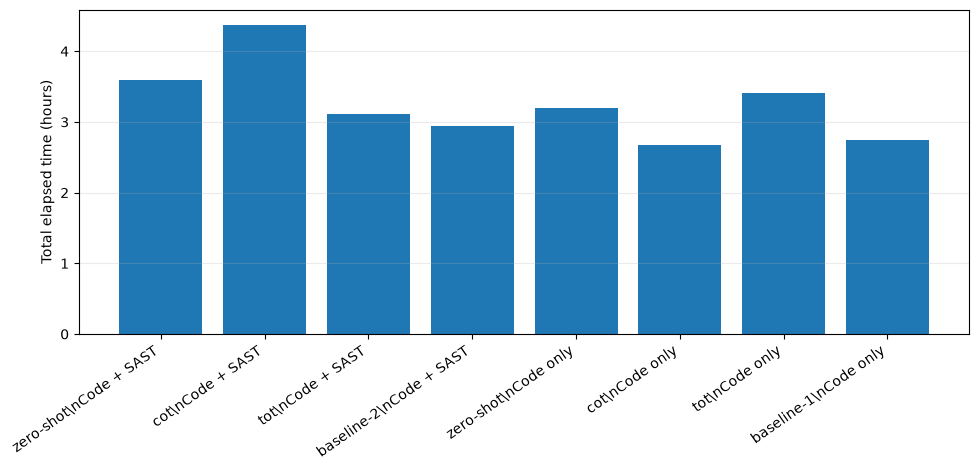

In [8]:
# Grafik deepseek: waktu inferensi
plot_df = dfm.copy()
labels = plot_df["scenario_label"] + "\\n" + plot_df["sast"].replace({"Code only":"Code only","Code + FindSecBugs":"Code + SAST"})
plt.figure(figsize=(10, 4.8))
plt.bar(labels, plot_df["elapsed_hours"])
plt.ylabel("Total elapsed time (hours)")
plt.xticks(rotation=35, ha="right")
plt.grid(axis="y", alpha=.25)
plt.tight_layout()
plt.show()


### DeepSeek Coder 6.7B: Predicted CWE — Code only

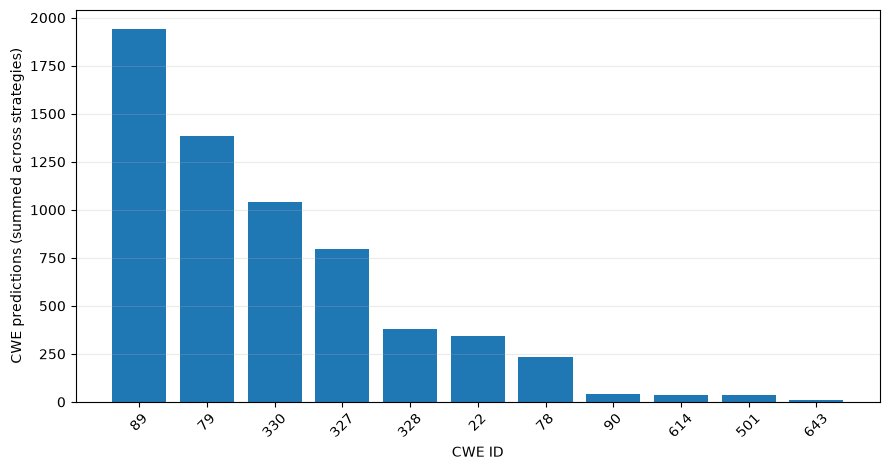

### DeepSeek Coder 6.7B: Predicted CWE — Code + FindSecBugs

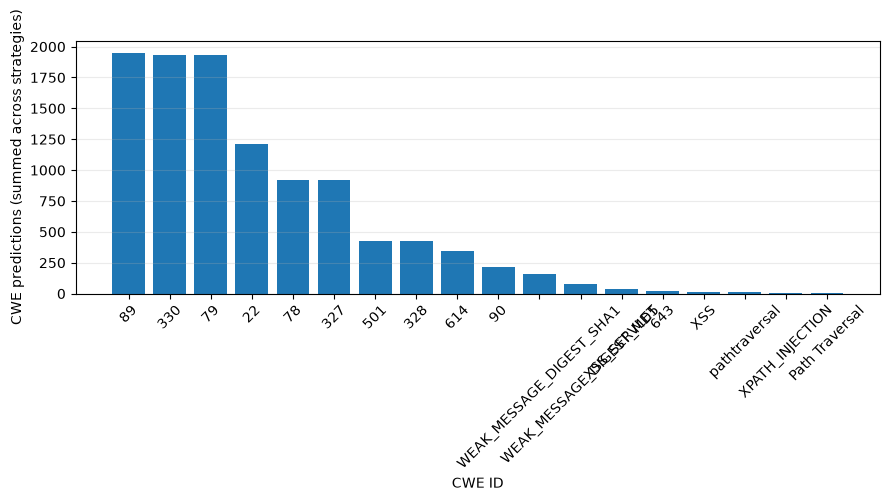

In [9]:
# Grafik deepseek: distribusi CWE yang diprediksi, satu grafik per kondisi input
from IPython.display import display, Markdown

for sast_condition in ["Code only", "Code + FindSecBugs"]:
    cwe_counts = {}
    for _, row in dfm[dfm["sast"] == sast_condition].iterrows():
        key = (row["model"], str(row["scenario"]), row["sast"])
        preds = predictions_by_scenario.get(key, [])
        for pred in preds:
            if pred.get("vulnerable") is True and pred.get("cwe") not in (None, ""):
                cwe = str(pred["cwe"]).replace("CWE-", "")
                cwe_counts[cwe] = cwe_counts.get(cwe, 0) + 1
    if not cwe_counts:
        print(f"No CWE data for condition {sast_condition}")
        continue
    display(Markdown(f"### DeepSeek Coder 6.7B: Predicted CWE — {sast_condition}"))
    counts = pd.Series(cwe_counts).sort_values(ascending=False)
    plt.figure(figsize=(9, 4.8))
    plt.bar(counts.index, counts.values)
    plt.xlabel("CWE ID")
    plt.ylabel("CWE predictions (summed across strategies)")
    plt.xticks(rotation=45)
    plt.grid(axis="y", alpha=.25)
    plt.tight_layout()
    plt.show()


# Analisis khusus: Gemma4 E4B (thinking aktif)

Seluruh grafik pada bagian ini hanya menampilkan model ini. Perbandingan DeepSeek dan Gemma tidak digabungkan dalam satu kanvas.

In [10]:
model_name = 'Gemma4 E4B (thinking aktif)'
dfm = summary[summary["model"] == model_name].copy()
dfm["scenario_label"] = dfm["scenario"].astype("string").fillna("unknown")

display(dfm[["scenario_label","sast","predictions_valid","valid_rate_pct",
             "predicted_vulnerable","predicted_not_vulnerable",
             "predicted_vulnerable_pct_of_valid","invalid_responses",
             "elapsed_hours"]].round(2))


,scenario_label,sast,predictions_valid,valid_rate_pct,predicted_vulnerable,predicted_not_vulnerable,predicted_vulnerable_pct_of_valid,invalid_responses,elapsed_hours
8,zero-shot,Code + FindSecBugs,2600,94.89,1917,683,73.73,140,5.70
9,cot,Code + FindSecBugs,2354,85.91,1702,652,72.30,386,6.89
10,tot,Code + FindSecBugs,2212,80.73,1494,718,67.54,528,9.79
11,baseline-2,Code + FindSecBugs,2273,82.96,1621,652,71.32,467,9.45
12,zero-shot,Code only,2731,99.67,1629,1102,59.65,9,6.22
13,cot,Code only,2733,99.74,1559,1174,57.04,7,6.81
14,tot,Code only,2726,99.49,1613,1113,59.17,14,6.73
15,baseline-1,Code only,2734,99.78,1692,1042,61.89,6,7.96


### Gemma 4 E4B (thinking enabled): Valid output rate per scenario


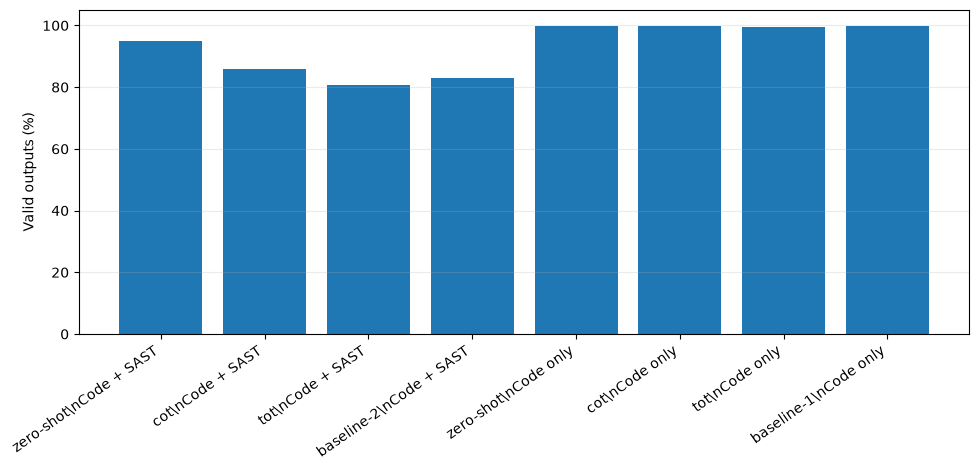

In [11]:
# Grafik gemma: tingkat keluaran valid
plot_df = dfm.copy()
labels = plot_df["scenario_label"] + "\\n" + plot_df["sast"].replace({"Code only":"Code only","Code + FindSecBugs":"Code + SAST"})
plt.figure(figsize=(10, 4.8))
plt.bar(labels, plot_df["valid_rate_pct"])
plt.ylabel("Valid outputs (%)")
plt.ylim(0, 105)
plt.xticks(rotation=35, ha="right")
plt.grid(axis="y", alpha=.25)
plt.tight_layout()
plt.show()


### Gemma 4 E4B (thinking enabled): Binary decision distribution


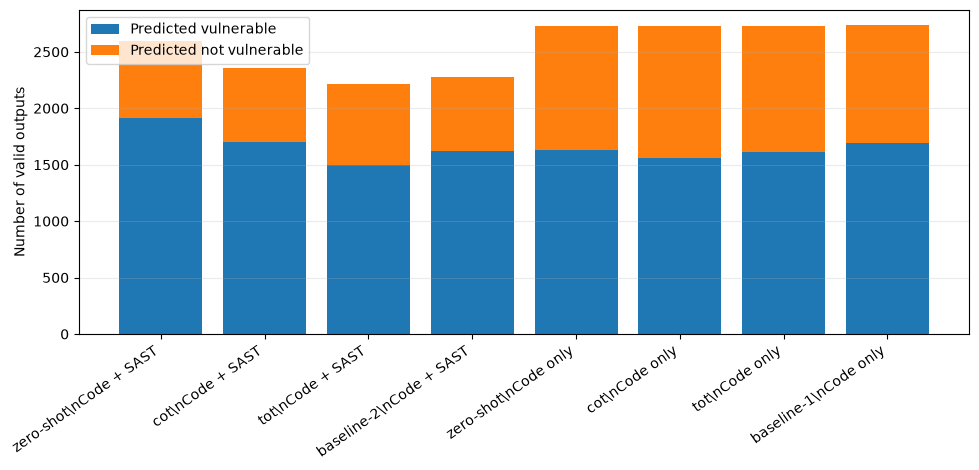

In [12]:
# Grafik gemma: jumlah label rentan yang dikeluarkan model
plot_df = dfm.copy()
labels = plot_df["scenario_label"] + "\\n" + plot_df["sast"].replace({"Code only":"Code only","Code + FindSecBugs":"Code + SAST"})
plt.figure(figsize=(10, 4.8))
plt.bar(labels, plot_df["predicted_vulnerable"], label="Predicted vulnerable")
plt.bar(labels, plot_df["predicted_not_vulnerable"],
        bottom=plot_df["predicted_vulnerable"], label="Predicted not vulnerable")
plt.ylabel("Number of valid outputs")
plt.xticks(rotation=35, ha="right")
plt.legend()
plt.grid(axis="y", alpha=.25)
plt.tight_layout()
plt.show()


### Gemma 4 E4B (thinking enabled): Share of valid outputs classified as vulnerable


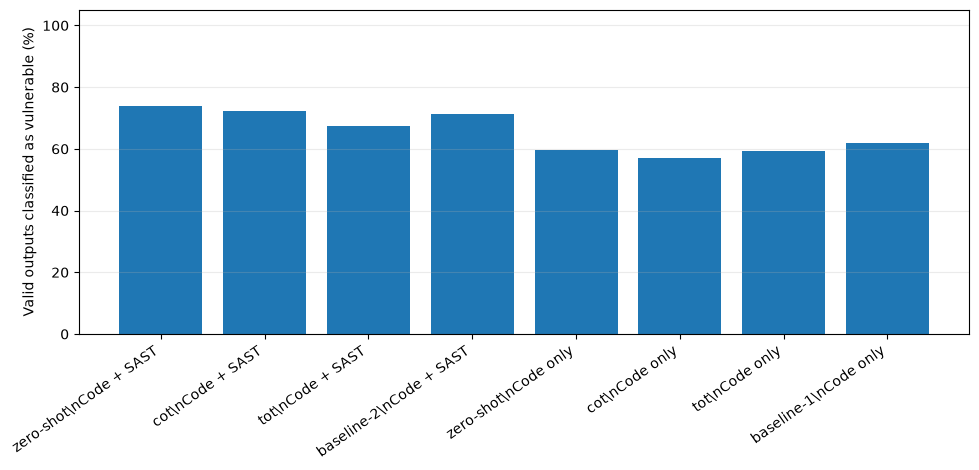

In [13]:
# Grafik gemma: proporsi prediksi rentan di antara keluaran valid
plot_df = dfm.copy()
labels = plot_df["scenario_label"] + "\\n" + plot_df["sast"].replace({"Code only":"Code only","Code + FindSecBugs":"Code + SAST"})
plt.figure(figsize=(10, 4.8))
plt.bar(labels, plot_df["predicted_vulnerable_pct_of_valid"])
plt.ylabel("Valid outputs classified as vulnerable (%)")
plt.ylim(0, 105)
plt.xticks(rotation=35, ha="right")
plt.grid(axis="y", alpha=.25)
plt.tight_layout()
plt.show()


### Gemma 4 E4B (thinking enabled): Total elapsed time per scenario


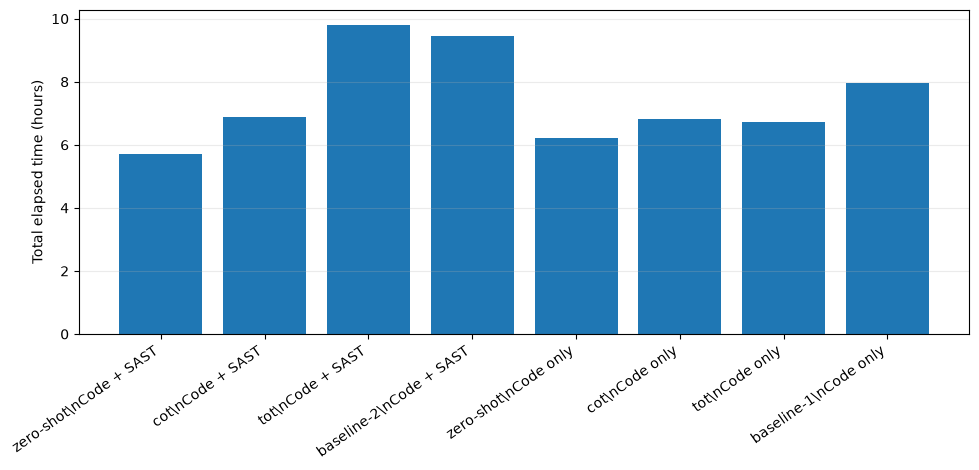

In [14]:
# Grafik gemma: waktu inferensi
plot_df = dfm.copy()
labels = plot_df["scenario_label"] + "\\n" + plot_df["sast"].replace({"Code only":"Code only","Code + FindSecBugs":"Code + SAST"})
plt.figure(figsize=(10, 4.8))
plt.bar(labels, plot_df["elapsed_hours"])
plt.ylabel("Total elapsed time (hours)")
plt.xticks(rotation=35, ha="right")
plt.grid(axis="y", alpha=.25)
plt.tight_layout()
plt.show()


### Gemma 4 E4B (thinking enabled): Predicted CWE — Code only

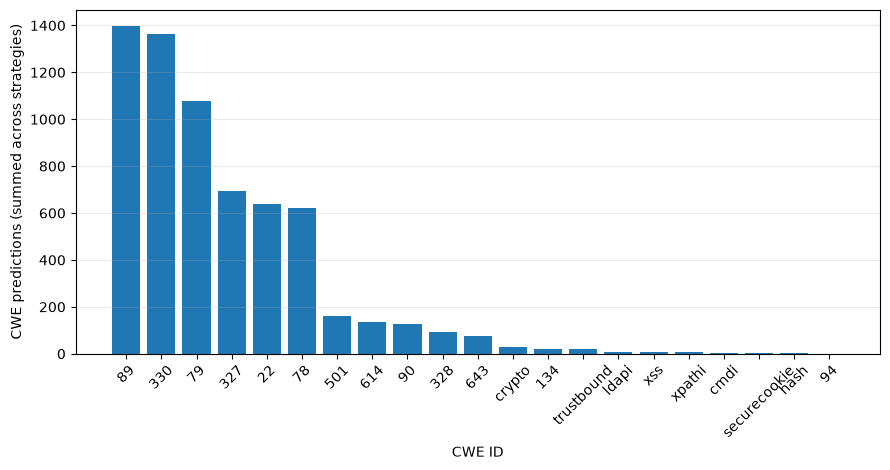

### Gemma 4 E4B (thinking enabled): Predicted CWE — Code + FindSecBugs

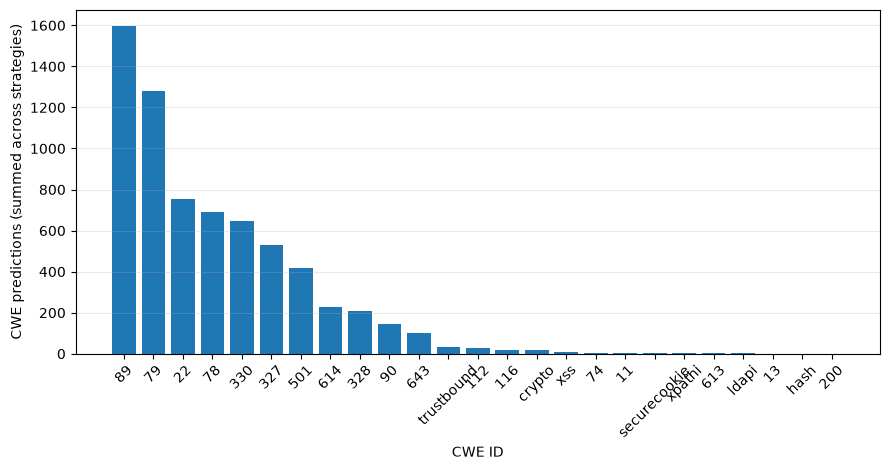

In [15]:
# Grafik gemma: distribusi CWE yang diprediksi, satu grafik per kondisi input
from IPython.display import display, Markdown

for sast_condition in ["Code only", "Code + FindSecBugs"]:
    cwe_counts = {}
    for _, row in dfm[dfm["sast"] == sast_condition].iterrows():
        key = (row["model"], str(row["scenario"]), row["sast"])
        preds = predictions_by_scenario.get(key, [])
        for pred in preds:
            if pred.get("vulnerable") is True and pred.get("cwe") not in (None, ""):
                cwe = str(pred["cwe"]).replace("CWE-", "")
                cwe_counts[cwe] = cwe_counts.get(cwe, 0) + 1
    if not cwe_counts:
        print(f"No CWE data for condition {sast_condition}")
        continue
    display(Markdown(f"### Gemma 4 E4B (thinking enabled): Predicted CWE — {sast_condition}"))
    counts = pd.Series(cwe_counts).sort_values(ascending=False)
    plt.figure(figsize=(9, 4.8))
    plt.bar(counts.index, counts.values)
    plt.xlabel("CWE ID")
    plt.ylabel("CWE predictions (summed across strategies)")
    plt.xticks(rotation=45)
    plt.grid(axis="y", alpha=.25)
    plt.tight_layout()
    plt.show()


## 4. Perbandingan prompting pada kondisi input yang sama

Bagian ini menyajikan perubahan deskriptif dari `Code only` ke `Code + FindSecBugs` untuk strategi yang sama. Selisih jumlah prediksi rentan tidak dapat langsung ditafsirkan sebagai peningkatan akurasi; perubahan itu baru dapat dinilai sebagai peningkatan atau penurunan performa setelah dibandingkan dengan ground truth.

In [16]:
paired = summary.pivot_table(
    index=["model","scenario"], columns="sast",
    values=["valid_rate_pct","predicted_vulnerable_pct_of_valid","elapsed_hours"],
    aggfunc="first", observed=False
)
display(paired.round(2))

# Selisih Code+SAST - Code only untuk setiap model dan strategi
diff_rows = []
for model in summary["model"].unique():
    for strategy in strategy_order:
        part = summary[(summary["model"] == model) & (summary["scenario"].astype(str) == strategy)]
        no_sast = part[part["sast"] == "Code only"]
        with_sast = part[part["sast"] == "Code + FindSecBugs"]
        if len(no_sast) == 1 and len(with_sast) == 1:
            a, b = no_sast.iloc[0], with_sast.iloc[0]
            diff_rows.append({
                "model": model, "scenario": strategy,
                "delta_valid_rate_pp": b["valid_rate_pct"] - a["valid_rate_pct"],
                "delta_predicted_vulnerable_pct_pp": b["predicted_vulnerable_pct_of_valid"] - a["predicted_vulnerable_pct_of_valid"],
                "delta_elapsed_hours": b["elapsed_hours"] - a["elapsed_hours"],
                "delta_invalid_responses": b["invalid_responses"] - a["invalid_responses"],
            })
display(pd.DataFrame(diff_rows).round(2))


elapsed_hours            \
sast                                   Code + FindSecBugs Code only   
model                       scenario                                  
DeepSeek Coder 6.7B         zero-shot                3.60      3.20   
                            cot                      4.37      2.67   
                            tot                      3.11      3.40   
                            baseline-1                NaN      2.74   
                            baseline-2               2.95       NaN   
Gemma4 E4B (thinking aktif) zero-shot                5.70      6.22   
                            cot                      6.89      6.81   
                            tot                      9.79      6.73   
                            baseline-1                NaN      7.96   
                            baseline-2               9.45       NaN   

                                       predicted_vulnerable_pct_of_valid  \
sast                                                  Code + FindSecBugs   
model                       scenario                                       
DeepSeek Coder 6.7B         zero-shot                              96.53   
                            cot                                    96.50   
                            tot                                    97.34   
                            baseline-1                               NaN   
                            baseline-2                             96.31   
Gemma4 E4B (thinking aktif) zero-shot                              73.73   
                            cot                                    72.30   
                            tot                                    67.54   
                            baseline-1                               NaN   
                            baseline-2                             71.32   

                                                     valid_rate_pct            
sast                                   Code only Code + FindSecBugs Code only  
model                       scenario                                           
DeepSeek Coder 6.7B         zero-shot      57.34             100.00    100.00  
                            cot            31.50             100.00    100.00  
                            tot            81.55             100.00     99.89  
                            baseline-1     57.66                NaN    100.00  
                            baseline-2       NaN             100.00       NaN  
Gemma4 E4B (thinking aktif) zero-shot      59.65              94.89     99.67  
                            cot            57.04              85.91     99.74  
                            tot            59.17              80.73     99.49  
                            baseline-1     61.89                NaN     99.78  
                            baseline-2       NaN              82.96       NaN

,model,scenario,delta_valid_rate_pp,delta_predicted_vulnerable_pct_pp,delta_elapsed_hours,delta_invalid_responses
0,DeepSeek Coder 6.7B,zero-shot,0.00,39.20,0.40,0
1,DeepSeek Coder 6.7B,cot,0.00,65.00,1.69,0
2,DeepSeek Coder 6.7B,tot,0.11,15.79,-0.30,-3
3,Gemma4 E4B (thinking aktif),zero-shot,-4.78,14.08,-0.52,131
4,Gemma4 E4B (thinking aktif),cot,-13.83,15.26,0.09,379
5,Gemma4 E4B (thinking aktif),tot,-18.76,8.37,3.05,514


## 5. Distribusi CWE per strategi

CWE yang muncul pada keluaran model belum tentu sesuai dengan ground truth. Notebook menghitung distribusi CWE yang **diprediksi** untuk setiap skenario, agar terlihat apakah strategi tertentu cenderung menghasilkan label tertentu atau menghasilkan label di luar kategori target.

In [17]:
cwe_rows = []
for (model, scenario, sast), preds in predictions_by_scenario.items():
    for pred in preds:
        if pred.get("vulnerable") is True and pred.get("cwe") not in (None, ""):
            cwe_rows.append({
                "model": model, "scenario": scenario, "sast": sast,
                "cwe": str(pred["cwe"]).replace("CWE-", ""),
                "test_name": pred.get("test_name")
            })
cwe_df = pd.DataFrame(cwe_rows)
if not cwe_df.empty:
    cwe_summary = (cwe_df.groupby(["model","scenario","sast","cwe"])
                   .size().rename("predicted_count").reset_index())
    display(cwe_summary.sort_values(["model","sast","scenario","predicted_count"],
                                    ascending=[True,True,True,False]))
else:
    print("Tidak ada prediksi CWE yang tersedia.")


,model,scenario,sast,cwe,predicted_count
18,DeepSeek Coder 6.7B,baseline-2,Code + FindSecBugs,89,483
17,DeepSeek Coder 6.7B,baseline-2,Code + FindSecBugs,79,482
13,DeepSeek Coder 6.7B,baseline-2,Code + FindSecBugs,330,459
10,DeepSeek Coder 6.7B,baseline-2,Code + FindSecBugs,22,273
11,DeepSeek Coder 6.7B,baseline-2,Code + FindSecBugs,327,261
...,...,...,...,...,...
222,Gemma4 E4B (thinking aktif),zero-shot,Code only,90,34
218,Gemma4 E4B (thinking aktif),zero-shot,Code only,643,19
211,Gemma4 E4B (thinking aktif),zero-shot,Code only,134,4
224,Gemma4 E4B (thinking aktif),zero-shot,Code only,xpathi,2


## 6. Analisis per sampel dan konsistensi prediksi

Bila nama sampel tersedia pada semua skenario, bagian ini mengukur seberapa sering keputusan biner antarstrategi berbeda. Ini adalah **konsistensi antarskenario**, bukan akurasi. Perbandingan hanya menggunakan sampel yang memiliki keluaran valid pada skenario yang sedang dibandingkan.

In [18]:
sample_frames = []
for (model, scenario, sast), preds in predictions_by_scenario.items():
    for p in preds:
        if p.get("test_name") is not None and isinstance(p.get("vulnerable"), bool):
            sample_frames.append({
                "model": model, "scenario": scenario, "sast": sast,
                "test_name": p["test_name"], "pred_vulnerable": p["vulnerable"],
                "pred_cwe": str(p.get("cwe") or "")
            })
sample_df = pd.DataFrame(sample_frames)

consistency_rows = []
for model in summary["model"].unique():
    for sast in ["Code only", "Code + FindSecBugs"]:
        sub = sample_df[(sample_df["model"] == model) & (sample_df["sast"] == sast)]
        if sub.empty:
            continue
        wide = sub.pivot_table(index="test_name", columns="scenario",
                               values="pred_vulnerable", aggfunc="first")
        available_strategies = [c for c in strategy_order if c in wide.columns]
        if len(available_strategies) < 2:
            continue
        aligned = wide[available_strategies].dropna()
        if aligned.empty:
            continue
        # Untuk tiap sampel, apakah semua strategi memberi keputusan yang sama?
        all_same = aligned.nunique(axis=1) == 1
        consistency_rows.append({
            "model": model,
            "sast": sast,
            "strategies_compared": ", ".join(available_strategies),
            "samples_with_all_compared_outputs": len(aligned),
            "same_binary_decision_all_strategies": int(all_same.sum()),
            "agreement_rate_pct": 100*all_same.mean()
        })
display(pd.DataFrame(consistency_rows).round(2))


,model,sast,strategies_compared,samples_with_all_compared_outputs,same_binary_decision_all_strategies,agreement_rate_pct
0,DeepSeek Coder 6.7B,Code only,"zero-shot, cot, tot, baseline-1",2737,1127,41.18
1,DeepSeek Coder 6.7B,Code + FindSecBugs,"zero-shot, cot, tot, baseline-2",2740,2712,98.98
2,Gemma4 E4B (thinking aktif),Code only,"zero-shot, cot, tot, baseline-1",2710,2036,75.13
3,Gemma4 E4B (thinking aktif),Code + FindSecBugs,"zero-shot, cot, tot, baseline-2",2072,1583,76.40


## 7. Metrik terhadap ground truth (opsional, direkomendasikan)

Untuk menghitung metrik yang sahih, siapkan CSV ground truth dengan satu baris per sampel dan kolom:
- `test_name`: misalnya `BenchmarkTest00001`
- `true_vulnerable`: nilai boolean (`True`/`False`) atau nilai yang dapat dikonversi ke boolean
- `true_cwe`: CWE numerik, misalnya `22`, untuk sampel rentan; kosong untuk benign jika sesuai definisi dataset.

Letakkan file bernama `ground_truth.csv` di folder notebook. Jika file tidak tersedia, sel berikut berhenti dengan pesan penjelasan. **Pastikan ground truth berasal dari label dataset asli, bukan hasil prediksi model atau inferensi dari nama sampel.**

In [19]:
from sklearn.metrics import (
    confusion_matrix, accuracy_score, precision_score, recall_score, f1_score,
    balanced_accuracy_score, matthews_corrcoef
)

ground_truth_candidates = [
    DATA_DIR.parent / "ground_truth.csv",
    Path.cwd() / "ground_truth.csv",
    Path.cwd() / "results" / "llm" / "raw" / "ground_truth.csv",
    Path("results/llm/raw/ground_truth.csv"),
]
gt_path = next((path for path in ground_truth_candidates if path.exists()), None)
if gt_path is not None:
    gt_path = gt_path.resolve()

if gt_path is None:
    print("ground_truth.csv tidak ditemukan. Metrik accuracy/precision/recall/F1/FPR/MCC tidak dihitung.")
    print("File ground truth diletakkan otomatis di results/llm/raw/ground_truth.csv jika tersedia.")
else:
    # Repository ground_truth.csv uses a descriptive comment as its first line, followed by data.
    gt_raw = pd.read_csv(gt_path, header=None, skiprows=1, usecols=range(4),
                         names=["test_name", "category", "true_vulnerable", "true_cwe"])

    def as_bool(x):
        if isinstance(x, bool): return x
        if pd.isna(x): return np.nan
        s = str(x).strip().lower()
        if s in {"true", "1", "yes", "vulnerable", "v"}: return True
        if s in {"false", "0", "no", "benign", "not vulnerable", "n"}: return False
        return np.nan

    gt = gt_raw.copy()
    gt["test_name"] = gt["test_name"].astype("string").str.strip()
    gt["true_vulnerable_bool"] = gt["true_vulnerable"].map(as_bool)
    gt["true_cwe_norm"] = gt["true_cwe"].astype("string").str.replace("CWE-", "", regex=False).str.strip()
    metric_rows, cwe_metric_rows = [], []
    for (model, scenario, sast), preds in predictions_by_scenario.items():
        pred_df = pd.DataFrame(preds)
        if pred_df.empty or not {"test_name", "vulnerable"}.issubset(pred_df.columns):
            continue
        pred_df = pred_df.rename(columns={"vulnerable":"pred_vulnerable", "cwe":"pred_cwe"})
        pred_df["test_name"] = pred_df["test_name"].astype("string").str.strip()
        pred_df["pred_vulnerable"] = pred_df["pred_vulnerable"].map(as_bool)
        merged = gt.merge(pred_df[["test_name", "pred_vulnerable", "pred_cwe"]], on="test_name", how="inner")
        merged = merged.dropna(subset=["true_vulnerable_bool", "pred_vulnerable"])
        if merged.empty:
            continue
        y_true = merged["true_vulnerable_bool"].astype(bool)
        y_pred = merged["pred_vulnerable"].astype(bool)
        tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[False, True]).ravel()
        metric_rows.append({
            "model": model, "scenario": scenario, "sast": sast,
            "n_evaluated": len(merged), "TP": int(tp), "FP": int(fp), "TN": int(tn), "FN": int(fn),
            "accuracy": accuracy_score(y_true, y_pred),
            "precision": precision_score(y_true, y_pred, zero_division=0),
            "recall": recall_score(y_true, y_pred, zero_division=0),
            "f1": f1_score(y_true, y_pred, zero_division=0),
            "FPR": fp/(fp+tn) if (fp+tn) else np.nan,
            "specificity": tn/(tn+fp) if (tn+fp) else np.nan,
            "balanced_accuracy": balanced_accuracy_score(y_true, y_pred),
            "MCC": matthews_corrcoef(y_true, y_pred),
        })
        vulnerable_pairs = merged[(merged["true_vulnerable_bool"] == True) & (merged["pred_vulnerable"] == True)].copy()
        if not vulnerable_pairs.empty:
            true_cwe = vulnerable_pairs["true_cwe_norm"].fillna("").astype(str).str.strip()
            pred_cwe = vulnerable_pairs["pred_cwe"].fillna("").astype(str).str.replace("CWE-", "", regex=False).str.strip()
            cwe_metric_rows.append({
                "model": model, "scenario": scenario, "sast": sast,
                "n_true_vuln_and_pred_vuln": len(vulnerable_pairs),
                "CWE_exact_match_rate": (true_cwe == pred_cwe).mean(),
            })

    metrics_df = pd.DataFrame(metric_rows)
    cwe_metrics_df = pd.DataFrame(cwe_metric_rows)
    if metrics_df.empty:
        print("Ground truth ditemukan, tetapi tidak ada pasangan sampel yang cocok dengan prediksi.")
    else:
        # Pisahkan tabel metrik biner berdasarkan model, lalu berdasarkan alat SAST.
        model_order = list(dict.fromkeys(metrics_df["model"].astype(str)))
        sast_order = list(dict.fromkeys(metrics_df["sast"].astype(str)))
        for model_name in model_order:
            print(f"\n=== Model: {model_name} ===")
            for sast_name in sast_order:
                table = metrics_df[
                    (metrics_df["model"] == model_name) &
                    (metrics_df["sast"] == sast_name)
                ]
                if table.empty:
                    continue
                print(f"-- SAST: {sast_name} --")
                display(table.drop(columns=["model", "sast"]).round(4))

        # Tabel CWE juga mengikuti pengelompokan model dan SAST agar mudah dibandingkan.
        if not cwe_metrics_df.empty:
            for model_name in model_order:
                print(f"\n=== CWE — Model: {model_name} ===")
                for sast_name in sast_order:
                    table = cwe_metrics_df[
                        (cwe_metrics_df["model"] == model_name) &
                        (cwe_metrics_df["sast"] == sast_name)
                    ]
                    if table.empty:
                        continue
                    print(f"-- SAST: {sast_name} --")
                    display(table.drop(columns=["model", "sast"]).round(4))



=== Model: DeepSeek Coder 6.7B ===
-- SAST: Code only --


,scenario,n_evaluated,TP,FP,TN,FN,accuracy,precision,recall,f1,FPR,specificity,balanced_accuracy,MCC
0,baseline-1,2740,887,693,632,528,0.5544,0.5614,0.6269,0.5923,0.5230,0.4770,0.5519,0.1050
3,cot,2740,468,395,930,947,0.5102,0.5423,0.3307,0.4109,0.2981,0.7019,0.5163,0.0351
5,tot,2737,1167,1065,260,245,0.5214,0.5228,0.8265,0.6405,0.8038,0.1962,0.5114,0.0293
7,zero-shot,2740,810,761,564,605,0.5015,0.5156,0.5724,0.5425,0.5743,0.4257,0.4990,-0.0019


-- SAST: Code + FindSecBugs --


,scenario,n_evaluated,TP,FP,TN,FN,accuracy,precision,recall,f1,FPR,specificity,balanced_accuracy,MCC
1,baseline-2,2740,1410,1229,96,5,0.5496,0.5343,0.9965,0.6956,0.9275,0.0725,0.5345,0.1828
2,cot,2740,1413,1231,94,2,0.5500,0.5344,0.9986,0.6962,0.9291,0.0709,0.5348,0.1890
4,tot,2740,1414,1253,72,1,0.5423,0.5302,0.9993,0.6928,0.9457,0.0543,0.5268,0.1664
6,zero-shot,2740,1413,1232,93,2,0.5496,0.5342,0.9986,0.6961,0.9298,0.0702,0.5344,0.1879



=== Model: Gemma4 E4B (thinking aktif) ===
-- SAST: Code only --


,scenario,n_evaluated,TP,FP,TN,FN,accuracy,precision,recall,f1,FPR,specificity,balanced_accuracy,MCC
8,baseline-1,2734,1301,391,931,111,0.8164,0.7689,0.9214,0.8383,0.2958,0.7042,0.8128,0.6437
11,cot,2733,1276,283,1038,136,0.8467,0.8185,0.9037,0.8590,0.2142,0.7858,0.8447,0.6960
13,tot,2726,1273,340,977,136,0.8254,0.7892,0.9035,0.8425,0.2582,0.7418,0.8227,0.6561
15,zero-shot,2731,1273,356,965,137,0.8195,0.7815,0.9028,0.8378,0.2695,0.7305,0.8167,0.6451


... (6 outputs left out)


=== CWE — Model: Gemma4 E4B (thinking aktif) ===
-- SAST: Code only --


,scenario,n_true_vuln_and_pred_vuln,CWE_exact_match_rate
8,baseline-1,1301,0.9016
11,cot,1276,0.9624
13,tot,1273,0.9615
15,zero-shot,1273,0.9686


-- SAST: Code + FindSecBugs --


,scenario,n_true_vuln_and_pred_vuln,CWE_exact_match_rate
9,baseline-2,1206,0.9096
10,cot,1254,0.9665
12,tot,1160,0.9810
14,zero-shot,1330,0.9714


## 7A. Grafik metrik klasifikasi untuk Bab IV

Bagian ini menghasilkan enam grafik yang digunakan pada Subbab 4.5 Bab IV:
- F1-score DeepSeek dan Gemma4;
- Recall DeepSeek dan Gemma4;
- False-positive rate (FPR) DeepSeek dan Gemma4.

Setiap grafik membandingkan kondisi **Code only** dengan **Code + FindSecBugs** pada konfigurasi prompt yang sama. `baseline-1` (code-only) dan `baseline-2` (hybrid) dipetakan ke satu label **Baseline**, karena keduanya merupakan konfigurasi kontrol pada dua kondisi input yang berbeda.

**Catatan interpretasi:** metrik dihitung dari keluaran valid yang berhasil dipasangkan dengan ground truth. Jumlah sampel evaluasi dapat berbeda antar skenario, khususnya pada Gemma4 hybrid. Karena itu, grafik harus dibaca bersama tabel cakupan keluaran valid dan tidak boleh dianggap sebagai perbandingan pada subset sampel identik.

### DeepSeek Coder 6.7B: F1-score by prompt configuration

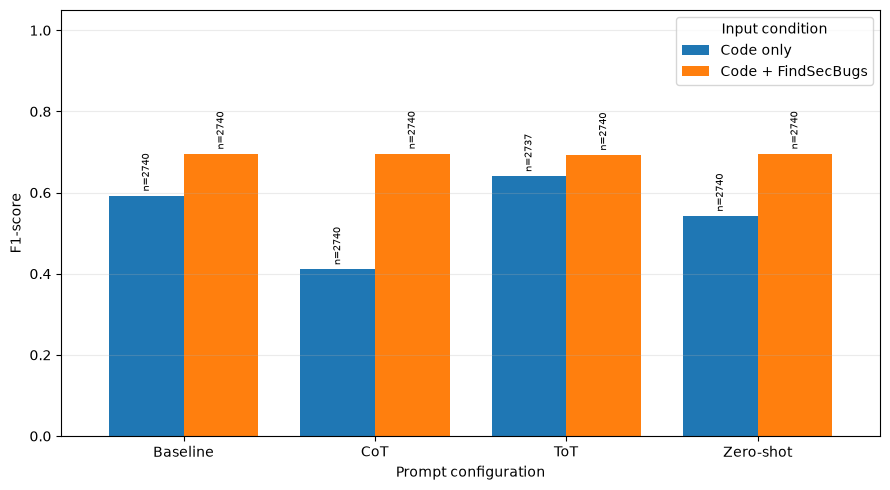

Grafik disimpan: figures/bab4_deepseek_f1.png


### DeepSeek Coder 6.7B: Recall by prompt configuration

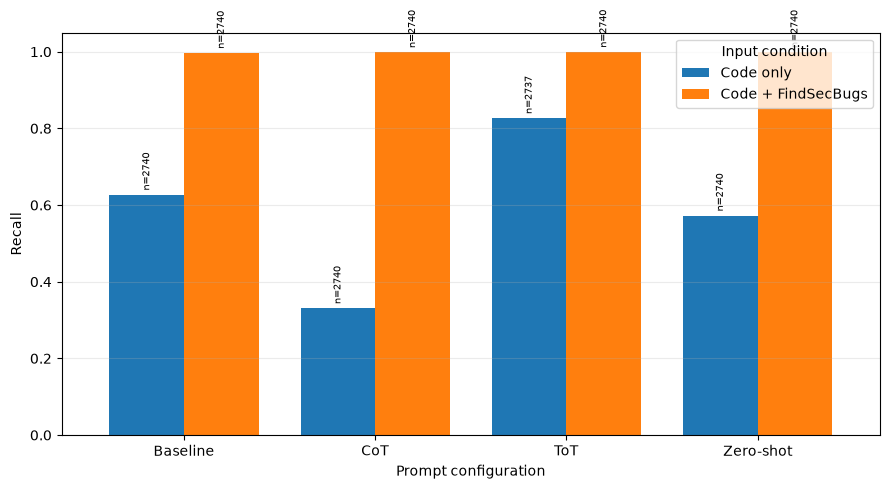

Grafik disimpan: figures/bab4_deepseek_recall.png


### DeepSeek Coder 6.7B: False-positive rate (FPR) by prompt configuration

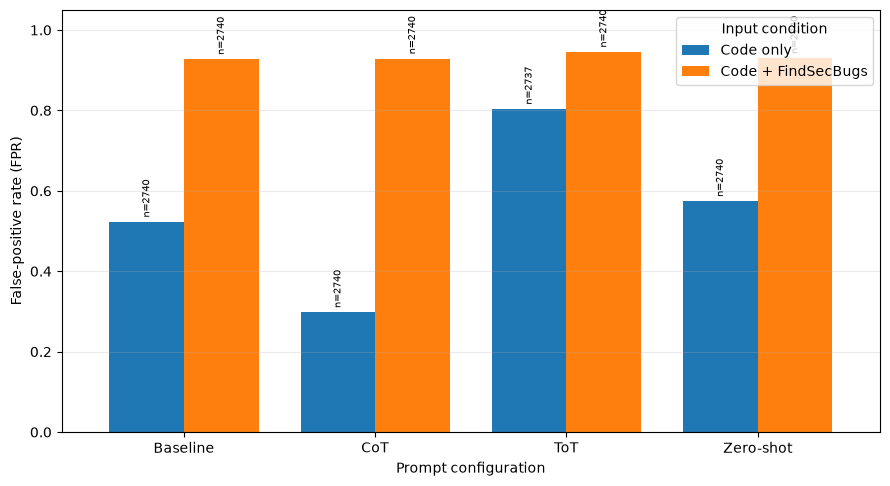

Grafik disimpan: figures/bab4_deepseek_fpr.png


### Gemma4 E4B (thinking aktif): F1-score by prompt configuration

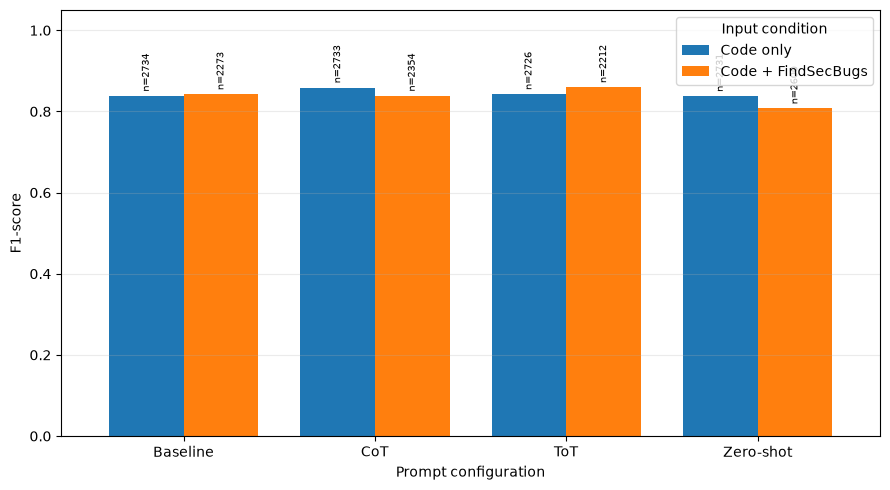

Grafik disimpan: figures/bab4_gemma4_f1.png


### Gemma4 E4B (thinking aktif): Recall by prompt configuration

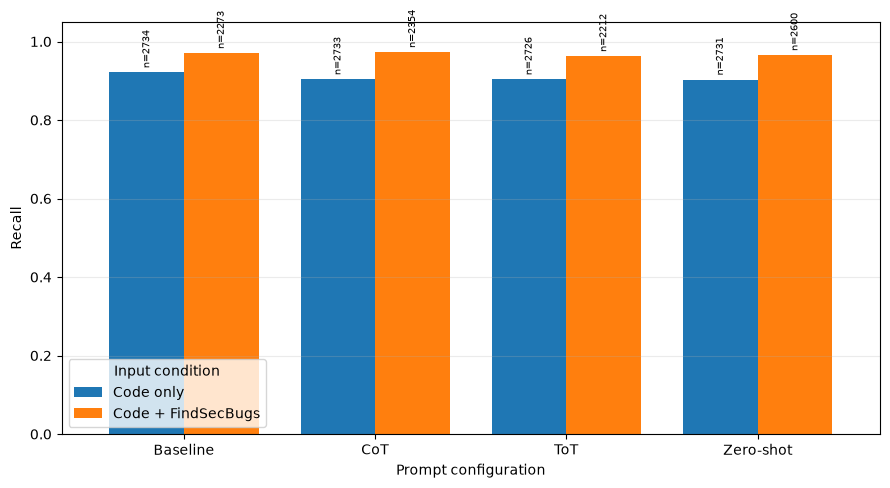

Grafik disimpan: figures/bab4_gemma4_recall.png


### Gemma4 E4B (thinking aktif): False-positive rate (FPR) by prompt configuration

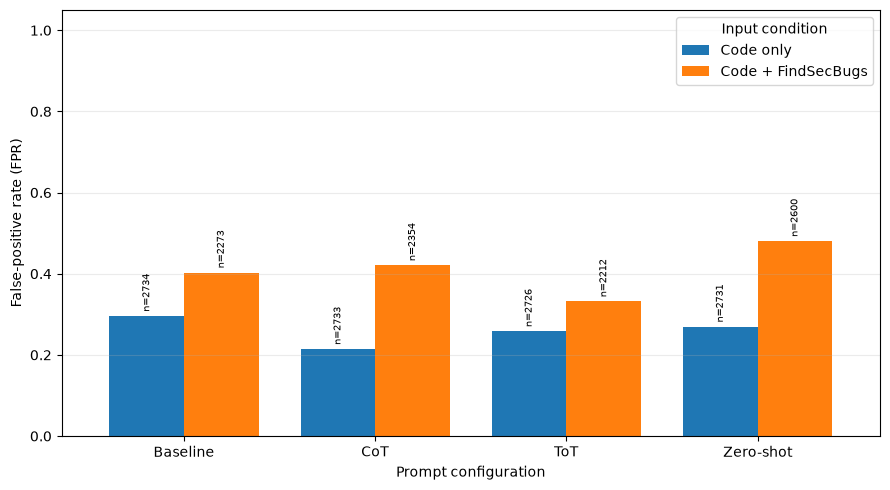

Grafik disimpan: figures/bab4_gemma4_fpr.png
Enam grafik Bab IV selesai dibuat jika kedua model dan ketiga metrik tersedia. Periksa n pada batang karena cakupan sampel antar kondisi dapat berbeda.


In [20]:
# Grafik metrik klasifikasi Bab IV: F1, Recall, dan FPR
# Sel ini dijalankan setelah cell "Metrik terhadap ground truth" (metrics_df).

if "metrics_df" not in globals() or metrics_df.empty:
    print("Grafik metrik Bab IV tidak dibuat: metrics_df belum tersedia. "
          "Pastikan ground_truth.csv ditemukan dan cell metrik telah dijalankan.")
else:
    import matplotlib.pyplot as plt
    from pathlib import Path

    # Samakan nama baseline antar kondisi input:
    # baseline-1 = code-only; baseline-2 = code + FindSecBugs.
    plot_metrics = metrics_df.copy()
    plot_metrics["strategy_plot"] = (
        plot_metrics["scenario"].astype(str)
        .replace({"baseline-1": "Baseline", "baseline-2": "Baseline",
                  "cot": "CoT", "tot": "ToT", "zero-shot": "Zero-shot"})
    )

    strategy_plot_order = ["Baseline", "CoT", "ToT", "Zero-shot"]
    condition_order = ["Code only", "Code + FindSecBugs"]
    model_plot_order = [
        "DeepSeek Coder 6.7B",
        "Gemma4 E4B (thinking aktif)"
    ]
    metric_specs = [
        ("f1", "F1-score", "F1"),
        ("recall", "Recall", "Recall"),
        ("FPR", "False-positive rate (FPR)", "FPR"),
    ]

    # Folder opsional untuk menyimpan gambar agar dapat digunakan kembali di Bab IV.
    figure_dir = Path("figures")
    figure_dir.mkdir(parents=True, exist_ok=True)

    for model_name in model_plot_order:
        model_data = plot_metrics[plot_metrics["model"] == model_name].copy()
        if model_data.empty:
            print(f"Tidak ada data metrik untuk {model_name}; grafik dilewati.")
            continue

        # Satu grafik untuk setiap metrik dan model.
        for metric_col, metric_label, metric_file in metric_specs:
            pivot = model_data.pivot_table(
                index="strategy_plot",
                columns="sast",
                values=metric_col,
                aggfunc="first"
            ).reindex(strategy_plot_order)

            # Pastikan kedua kondisi input tersedia sebagai kolom, meski ada data yang hilang.
            for condition in condition_order:
                if condition not in pivot.columns:
                    pivot[condition] = np.nan
            pivot = pivot[condition_order]

            ax = pivot.plot(
                kind="bar",
                figsize=(9, 5),
                width=0.78
            )
            ax.set_xlabel("Prompt configuration")
            ax.set_ylabel(metric_label)
            ax.set_ylim(0, 1.05)
            ax.set_xticklabels(strategy_plot_order, rotation=0)
            ax.grid(axis="y", alpha=0.25)
            ax.legend(
                ["Code only", "Code + FindSecBugs"],
                title="Input condition",
                loc="best"
            )

            # Cantumkan n evaluasi pada setiap batang untuk memperlihatkan perbedaan coverage.
            n_lookup = {
                (row["strategy_plot"], row["sast"]): int(row["n_evaluated"])
                for _, row in model_data.iterrows()
            }
            for container, condition in zip(ax.containers, condition_order):
                for bar, strategy in zip(container, strategy_plot_order):
                    value = bar.get_height()
                    if np.isfinite(value):
                        n_value = n_lookup.get((strategy, condition))
                        label = f"n={n_value}" if n_value is not None else ""
                        ax.annotate(
                            label,
                            (bar.get_x() + bar.get_width() / 2, value),
                            xytext=(0, 3),
                            textcoords="offset points",
                            ha="center",
                            va="bottom",
                            fontsize=7,
                            rotation=90
                        )

            from IPython.display import display, Markdown
            display(Markdown(f"### {model_name}: {metric_label} by prompt configuration"))

            plt.tight_layout()
            safe_model = (
                "deepseek" if "DeepSeek" in model_name else "gemma4"
            )
            output_path = figure_dir / f"bab4_{safe_model}_{metric_file.lower()}.png"
            plt.savefig(output_path, dpi=300, bbox_inches="tight")
            plt.show()
            plt.close()
            print(f"Grafik disimpan: {output_path}")

    print(
        "Enam grafik Bab IV selesai dibuat jika kedua model dan ketiga metrik tersedia. "
        "Periksa n pada batang karena cakupan sampel antar kondisi dapat berbeda."
    )


### Hasil FindSecBugs saja (baseline SAST)

Bagian ini menghitung metrik klasifikasi berdasarkan hasil traditional SAST dari `findsecbugs-security-per-test.csv`, tanpa menggabungkannya dengan prediksi LLM.

In [21]:
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score

def to_bool(value):
    if isinstance(value, bool):
        return value
    if pd.isna(value):
        return np.nan
    text = str(value).strip().lower()
    if text in {"true", "1", "yes", "vulnerable", "v", "detected"}:
        return True
    if text in {"false", "0", "no", "benign", "not detected"}:
        return False
    return np.nan

findsecbugs_candidates = [
    Path.cwd() / "results" / "traditional" / "security" / "findsecbugs-security-per-test.csv",
    Path("results/traditional/security/findsecbugs-security-per-test.csv"),
    DATA_DIR.parent.parent.parent / "traditional" / "security" / "findsecbugs-security-per-test.csv",
]
findsecbugs_path = next((path for path in findsecbugs_candidates if path.exists()), None)
if findsecbugs_path is None:
    print("Berkas hasil FindSecBugs saja tidak ditemukan.")
else:
    fsb = pd.read_csv(findsecbugs_path)
    fsb["test_name"] = fsb["test_name"].astype("string").str.strip()
    fsb["y_pred"] = fsb["detected"].map(to_bool)
    fsb["y_true"] = fsb["real_vulnerability"].map(to_bool)
    fsb = fsb.dropna(subset=["y_true", "y_pred"])

    y_true = fsb["y_true"].astype(bool)
    y_pred = fsb["y_pred"].astype(bool)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[False, True]).ravel()

    findsecbugs_metrics = pd.DataFrame([{
        "SAST": "FindSecBugs only",
        "n_evaluated": len(fsb),
        "TP": int(tp), "FP": int(fp), "TN": int(tn), "FN": int(fn),
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score(y_true, y_pred, zero_division=0),
        "f1": f1_score(y_true, y_pred, zero_division=0),
        "FPR": fp/(fp+tn) if (fp+tn) else np.nan,
        "specificity": tn/(tn+fp) if (tn+fp) else np.nan,
        "balanced_accuracy": balanced_accuracy_score(y_true, y_pred),
    }])
    print(f"FindSecBugs-only result: {findsecbugs_path.resolve()}")
    display(findsecbugs_metrics.round(4))

    vulnerable_pairs = fsb[(fsb["y_true"] == True) & (fsb["y_pred"] == True)].copy()
    if not vulnerable_pairs.empty:
        true_cwe = vulnerable_pairs["cwe"].astype("string").str.replace("CWE-", "", regex=False).str.strip()
        # Keluaran tradisional tidak menyediakan prediksi CWE terpisah per temuan;
        # gunakan CWE ground-truth kategori yang dilaporkan sebagai kecocokan SAST.
        detected_cwe = vulnerable_pairs["cwe"].astype("string").str.replace("CWE-", "", regex=False).str.strip()
        findsecbugs_cwe = pd.DataFrame([{
            "SAST": "FindSecBugs only",
            "n_true_vuln_and_detected": len(vulnerable_pairs),
            "CWE_exact_match_rate": (true_cwe == detected_cwe).mean(),
        }])
        display(findsecbugs_cwe.round(4))

FindSecBugs-only result: /home/nasyikhqusyairy/Projects/repositories/sast-llm-benchmark/results/traditional/security/findsecbugs-security-per-test.csv


,SAST,n_evaluated,TP,FP,TN,FN,accuracy,precision,recall,f1,FPR,specificity,balanced_accuracy
0,FindSecBugs only,2740,1410,1189,136,5,0.5642,0.5425,0.9965,0.7025,0.8974,0.1026,0.5496


,SAST,n_true_vuln_and_detected,CWE_exact_match_rate
0,FindSecBugs only,1410,1.0


## 8. Ringkasan interpretasi yang dapat dipertanggungjawabkan

Gunakan panduan ini saat menulis hasil:
- `valid_rate_pct` mengukur keberhasilan keluaran memenuhi parser/format yang diharapkan, bukan keberhasilan deteksi kerentanan.
- `predicted_vulnerable` dan `predicted_vulnerable_pct_of_valid` mengukur kecenderungan model memberi label rentan, bukan true positive rate.
- `elapsed_hours` adalah waktu total pada metadata skenario; jangan menyimpulkan throughput per sampel tanpa memeriksa apakah waktu mencakup retry, antrean, dan pemrosesan lainnya.
- Distribusi CWE adalah label yang diprediksi. Akurasi CWE perlu dibandingkan dengan CWE ground truth.
- Hasil Gemma4 E4B dengan thinking aktif merupakan kondisi eksperimen berbeda dari DeepSeek Coder 6.7B dengan thinking nonaktif. Karena model dan pengaturan berpikir berbeda, perbedaan hasil tidak boleh diatribusikan hanya kepada strategi prompting.
- Untuk klaim utama tentang dampak prompting, bandingkan strategi di dalam model yang sama dan kondisi input yang sama. Analisis pengaruh SAST dengan membandingkan Code only vs Code + FindSecBugs pada model dan strategi yang sama.
- Jika ingin menyimpulkan peningkatan/penurunan performa, gunakan metrik ground-truth dan laporkan jumlah sampel yang benar-benar dievaluasi pada setiap skenario.

- Grafik F1, recall, dan FPR untuk Bab IV dibuat pada bagian **7A** setelah metrik terhadap ground truth dihitung. Grafik tersebut menggunakan keluaran valid yang berhasil dipasangkan dengan ground truth; periksa nilai `n` pada setiap batang sebelum menafsirkan selisih antarkondisi.


In [22]:
# Ringkasan otomatis per model (deskriptif; tidak mengklaim akurasi)
for model_name, group in summary.groupby("model"):
    print("\n" + "="*80)
    print(model_name)
    print("="*80)
    best_valid = group.loc[group["valid_rate_pct"].idxmax()]
    fastest = group.loc[group["elapsed_seconds"].idxmin()]
    most_vuln = group.loc[group["predicted_vulnerable_pct_of_valid"].idxmax()]
    print(f"Tingkat keluaran valid tertinggi: {best_valid['scenario']} | {best_valid['sast']} "
          f"({best_valid['valid_rate_pct']:.2f}%)")
    print(f"Waktu total terendah: {fastest['scenario']} | {fastest['sast']} "
          f"({fastest['elapsed_hours']:.2f} jam)")
    print(f"Proporsi prediksi rentan tertinggi: {most_vuln['scenario']} | {most_vuln['sast']} "
          f"({most_vuln['predicted_vulnerable_pct_of_valid']:.2f}%)")
    print("Catatan: ketiganya indikator deskriptif, bukan penilaian akurasi.")



DeepSeek Coder 6.7B
Tingkat keluaran valid tertinggi: zero-shot | Code + FindSecBugs (100.00%)
Waktu total terendah: cot | Code only (2.67 jam)
Proporsi prediksi rentan tertinggi: tot | Code + FindSecBugs (97.34%)
Catatan: ketiganya indikator deskriptif, bukan penilaian akurasi.

Gemma4 E4B (thinking aktif)
Tingkat keluaran valid tertinggi: baseline-1 | Code only (99.78%)
Waktu total terendah: zero-shot | Code + FindSecBugs (5.70 jam)
Proporsi prediksi rentan tertinggi: zero-shot | Code + FindSecBugs (73.73%)
Catatan: ketiganya indikator deskriptif, bukan penilaian akurasi.
